# BTCUSDT — exploration and prediction

In [1]:
# Setup
import sys
sys.path.insert(0, ".")          # so `import research` finds research.py
import research as R
import features as F
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

ROOT = "./data"
pd.set_option("display.width", 140)

## Creating inventory
Initial analysis

In [2]:
inv = R.inventory(ROOT)
print(inv['stream'].value_counts())
inv.info()
inv.head()



stream
agg_trade      224
book_ticker    224
depth          224
mark_price     112
force_order    109
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 893 entries, 0 to 892
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   venue   893 non-null    str    
 1   symbol  893 non-null    str    
 2   stream  893 non-null    str    
 3   date    893 non-null    str    
 4   hour    893 non-null    str    
 5   rows    893 non-null    int64  
 6   mb      893 non-null    float64
dtypes: float64(1), int64(1), str(5)
memory usage: 78.9 KB


,venue,symbol,stream,date,hour,rows,mb
0,futures,BTCUSDT,agg_trade,2026-08-06,20,4612,0.2
1,futures,BTCUSDT,agg_trade,2026-08-06,21,16553,0.6
2,futures,BTCUSDT,agg_trade,2026-08-06,22,13878,0.5
3,futures,BTCUSDT,agg_trade,2026-08-06,23,16573,0.6
4,futures,BTCUSDT,agg_trade,2026-08-07,00,22265,0.8


## Creating dataframe of Best Bid and Offer

Chose last 80hrs as near continuous data

creating 1s grid

In [3]:
# Cell 4 — spot BBO (the target instrument) on the mandated 1-second grid
bbo = R.add_mid(R.load(ROOT, "spot", stream="book_ticker", last_hours=80))
print(f"{len(bbo):,} source rows, "
      f"{(bbo.recv_ns.max()-bbo.recv_ns.min())/1e9/3600:.2f} h span, "
      f"{R.contiguous_blocks(bbo).nunique()} contiguous block(s)")

grid = R.grid_labels(bbo, horizon_s=5.0, freq_s=1.0)
R.grid_report(grid)
grid.head(10)
grid.info()

14,072,092 source rows, 79.95 h span, 5 contiguous block(s)
grid points          : 287,831
  no prior obs / stale: 198 (0.07%)
  dropped, incl. tail : 380 (0.13%)
  usable labels       : 287,451 (99.87%)
staleness of sampled quote: p50=37ms p99=1039ms
y_bps: std=0.606 min=-15.15 max=26.14 |y|<0.1bps=80.8%
<class 'pandas.DataFrame'>
RangeIndex: 287831 entries, 0 to 287830
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   t_ns          287831 non-null  int64              
 1   mid           287633 non-null  float64            
 2   mid_fwd       287451 non-null  float64            
 3   staleness_ns  287831 non-null  int64              
 4   sess          287633 non-null  str                
 5   y_bps         287451 non-null  float64            
 6   t             287831 non-null  datetime64[ns, UTC]
dtypes: datetime64[ns, UTC](1), float64(3), int64(2), str(1)
memory usage: 18.7 MB


### Loading the rest of the data we will use

In [4]:
fut = R.add_mid(R.load(ROOT, "futures", stream="book_ticker", last_hours=80))
tr_spot = R.load(ROOT, "spot",    stream="agg_trade",  last_hours=80)
tr_fut  = R.load(ROOT, "futures", stream="agg_trade",  last_hours=80)
mark    = R.load(ROOT, "futures", stream="mark_price", last_hours=80)

### Check how much unusable data we have

This is the data we want to drop

In [5]:
bad = grid[grid.staleness_ns < 0]
print(f"{len(bad):,} unusable grid points")
if len(bad):
    blk = (bad.t_ns.diff() > 2e9).cumsum()
    runs = bad.groupby(blk).t_ns.agg(['min','max','count'])
    runs['minutes'] = (runs['max']-runs['min'])/1e9/60
    print(runs.assign(start=pd.to_datetime(runs['min'],unit='ns',utc=True))
              [['start','count','minutes']].to_string())

198 unusable grid points
                         start  count   minutes
t_ns                                           
0    2026-08-08 08:04:33+00:00      1  0.000000
1    2026-08-08 08:11:00+00:00      1  0.000000
2    2026-08-08 08:58:47+00:00      1  0.000000
3    2026-08-08 09:00:13+00:00      1  0.000000
4    2026-08-08 09:02:47+00:00      1  0.000000
5    2026-08-08 09:47:33+00:00      1  0.000000
6    2026-08-08 10:09:18+00:00      1  0.000000
7    2026-08-08 10:10:30+00:00      1  0.000000
8    2026-08-08 10:10:45+00:00      1  0.000000
9    2026-08-08 10:10:51+00:00      1  0.000000
10   2026-08-08 10:15:30+00:00      1  0.000000
11   2026-08-08 10:20:40+00:00      1  0.000000
12   2026-08-08 10:21:05+00:00      1  0.000000
13   2026-08-08 10:22:41+00:00      1  0.000000
14   2026-08-08 10:28:13+00:00      1  0.000000
15   2026-08-08 10:28:23+00:00      1  0.000000
16   2026-08-08 12:13:36+00:00      1  0.000000
17   2026-08-08 12:37:00+00:00      1  0.000000
18   2026-08-08

#### Create features and make sure that causality is in right direction

In [6]:
grid = R.grid_labels(bbo, horizon_s=5.0, freq_s=1.0)
X = F.build(grid, bbo, fut, tr_spot, tr_fut, mark)
F.assert_causal(X)

causality OK — every joined observation is at or before its grid point


List of all columns

In [7]:
print(X.columns)

Index(['t_ns', 'mid', 'mid_fwd', 'staleness_ns', 'sess', 'y_bps', 't', 'spot_age_s', 'spot_mid', 'spot_spread_bps', 'spot_imbalance',
       'spot_wmid_dev_bps', 'fut_age_s', 'fut_mid', 'fut_spread_bps', 'fut_imbalance', 'fut_wmid_dev_bps', 'spot_signed_vol_1s',
       'spot_n_trades_1s', 'spot_ofi_1s', 'spot_signed_vol_5s', 'spot_n_trades_5s', 'spot_ofi_5s', 'spot_signed_vol_60s',
       'spot_n_trades_60s', 'spot_ofi_60s', 'fut_signed_vol_1s', 'fut_n_trades_1s', 'fut_ofi_1s', 'fut_signed_vol_5s', 'fut_n_trades_5s',
       'fut_ofi_5s', 'fut_signed_vol_60s', 'fut_n_trades_60s', 'fut_ofi_60s', 'rv_10s_bps', 'rv_60s_bps', 'ret_1s_bps', 'basis_bps',
       'funding_rate'],
      dtype='str')


All features being considered in the final model, drop missing values

In [8]:
print(F.FEATURES)
d = X.dropna(subset=F.FEATURES + ["y_bps"])
Xf, y = d[F.FEATURES], d["y_bps"]

['spot_imbalance', 'spot_spread_bps', 'spot_wmid_dev_bps', 'fut_imbalance', 'fut_spread_bps', 'fut_wmid_dev_bps', 'basis_bps', 'spot_ofi_1s', 'spot_ofi_5s', 'fut_ofi_1s', 'fut_ofi_5s', 'fut_ofi_60s', 'fut_n_trades_5s', 'spot_n_trades_5s', 'rv_10s_bps', 'rv_60s_bps', 'ret_1s_bps']


Vast majority of datapoints show no change

In [9]:
print(y.value_counts())

y_bps
 0.000000    222592
 0.307659        12
-0.307461        12
-0.615839        11
 1.230845        11
              ...  
 3.344791         1
 0.365108         1
 0.055080         1
 0.258084         1
 0.314728         1
Name: count, Length: 29792, dtype: int64


### Test-train split

Walk forward so that it trains on past and validates on future

Consistent minute long gaps between folds so future never goes into past features


In [10]:
import splits as S

d = X.dropna(subset=F.FEATURES + ["y_bps"])
dev, hold = S.frozen_holdout(d, frac=0.20, horizon_s=5.0, embargo_s=60.0)
# hold goes in a drawer until the model is final

print(S.describe_splits(dev, n_splits=5).to_string(index=False))


frozen holdout, by=rows, at 2026-08-10 23:58:44+00:00
  (row-based cut 2026-08-10 23:58:44+00:00, time-based cut 2026-08-10 23:57:45+00:00, differ by 1.0 min)
  develop: 229,746 rows   holdout: 57,453 rows (20.0% of samples)
  purged+embargoed at the boundary: 64 rows
 fold  n_train  n_val                 train_end                 val_start  gap_s
    0    38227  38291 2026-08-08 18:39:27+00:00 2026-08-08 18:40:32+00:00   65.0
    1    76518  38291 2026-08-09 05:19:55+00:00 2026-08-09 05:21:00+00:00   65.0
    2   114809  38291 2026-08-09 16:00:02+00:00 2026-08-09 16:01:07+00:00   65.0
    3   153100  38291 2026-08-10 02:39:43+00:00 2026-08-10 02:40:48+00:00   65.0
    4   191391  38291 2026-08-10 13:18:09+00:00 2026-08-10 13:19:14+00:00   65.0


### Baseline

Ridge baseline and fits on wlak-forward validation scheme

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import model as M

rows = []
for i, (tr, va) in enumerate(S.purged_walk_forward(dev, n_splits=5)):
    m = M.make_model()
    m.fit(dev.loc[tr, F.FEATURES], dev.loc[tr, "y_bps"])
    pred = m.predict(dev.loc[va, F.FEATURES])
    rows.append({"fold": i, **S.evaluate(dev.loc[va, "y_bps"], pred, theta=1.0)})

cv = pd.DataFrame(rows)
print(cv.round(5).to_string(index=False))
print("\nmean:", cv.r2_zero.mean().round(5), " std:", cv.r2_zero.std().round(5))

 fold  r2_zero      ic  ic_spearman  dir_acc_gt_1.0bp  n_gt_1.0bp  rmse_bps     n
    0  0.01594 0.15516      0.31652           0.77255         510   0.25889 38291
    1  0.03484 0.18444      0.35927           0.83247         579   0.28441 38291
    2  0.03756 0.22888      0.43652           0.79421        3246   0.72708 38291
    3  0.07814 0.28932      0.47513           0.80791        3337   0.59196 38291
    4  0.05668 0.25007      0.40605           0.76048        5607   0.90686 38291

mean: 0.04463  std: 0.02365


### Feature Engineering

First look at time series aspect of the data

Histogram of label

<class 'pandas.DataFrame'>
RangeIndex: 229746 entries, 0 to 229745
Data columns (total 40 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   t_ns                 229746 non-null  int64              
 1   mid                  229746 non-null  float64            
 2   mid_fwd              229746 non-null  float64            
 3   staleness_ns         229746 non-null  int64              
 4   sess                 229746 non-null  str                
 5   y_bps                229746 non-null  float64            
 6   t                    229746 non-null  datetime64[ns, UTC]
 7   spot_age_s           229746 non-null  float64            
 8   spot_mid             229746 non-null  float64            
 9   spot_spread_bps      229746 non-null  float64            
 10  spot_imbalance       229746 non-null  float64            
 11  spot_wmid_dev_bps    229746 non-null  float64            
 12  fut_age_s    

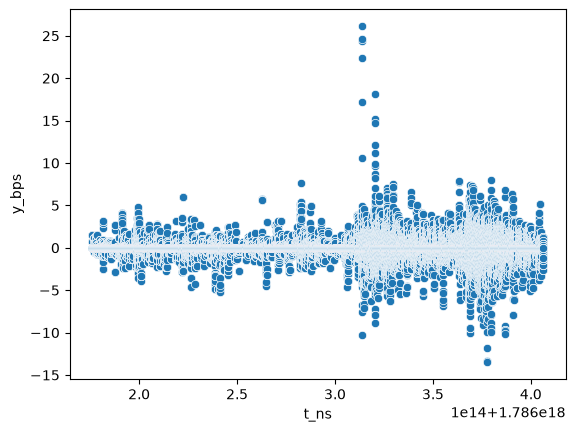

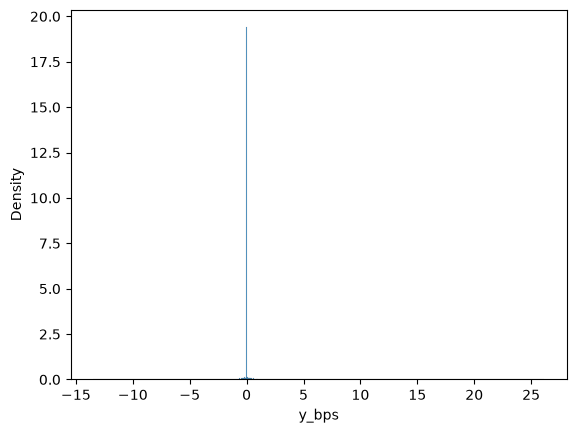

In [13]:
import seaborn as sns


print(dev.info())
sns.scatterplot(data= dev, x="t_ns", y="y_bps")
plt.show()

sns.histplot(dev["y_bps"],stat="density")
plt.show()

### Time-based structure

Ends up showing very little day-by-day correlation

In [14]:
dev2 = dev.copy()
dev2["hr"] = dev2.t.dt.hour
by_hour = dev2.groupby([dev2.t.dt.date, "hr"]).y_bps.mean().unstack(0)
print(by_hour.round(3).to_string())
print("\ncorrelation between days:")
print(by_hour.corr().round(2).to_string())

t   2026-08-08  2026-08-09  2026-08-10
hr                                    
0          NaN       0.002       0.017
1          NaN      -0.024       0.049
2          NaN      -0.009      -0.022
3          NaN      -0.007      -0.026
4          NaN      -0.001       0.006
5          NaN       0.004       0.028
6          NaN       0.010       0.035
7          NaN      -0.005      -0.022
8        0.010      -0.000       0.009
9       -0.000       0.012      -0.059
10       0.002       0.018       0.010
11      -0.008      -0.002       0.023
12       0.009       0.002      -0.054
13       0.001       0.056      -0.066
14       0.024       0.008       0.014
15      -0.010      -0.007      -0.076
16       0.001       0.001      -0.076
17       0.007      -0.007       0.008
18      -0.016       0.000      -0.014
19       0.007      -0.004       0.034
20       0.002      -0.009       0.024
21      -0.014       0.014      -0.037
22      -0.015      -0.023       0.006
23       0.003      -0.03

### Feature Interactions

Correlations indicating which features are likely to interact

<Axes: >

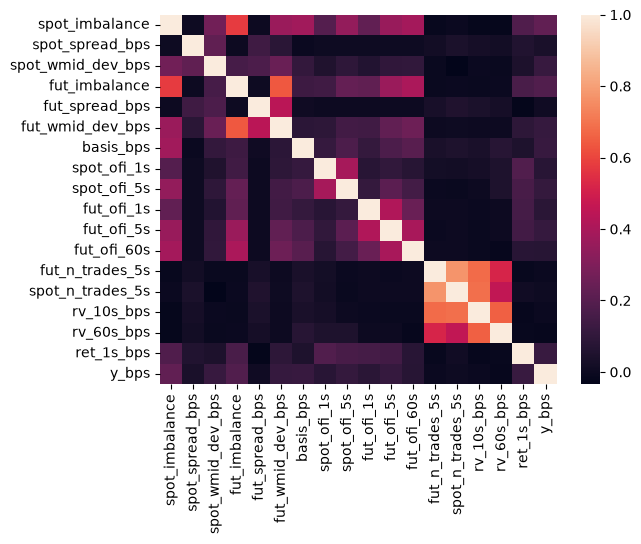

In [15]:
sns.heatmap(dev[F.FEATURES + ["y_bps"]].corr())

### Heatmaps exploring Interaction Terms 

Look at those with high correlations

- Imbalance vs spread

- Imbalance vs volatility

- etc


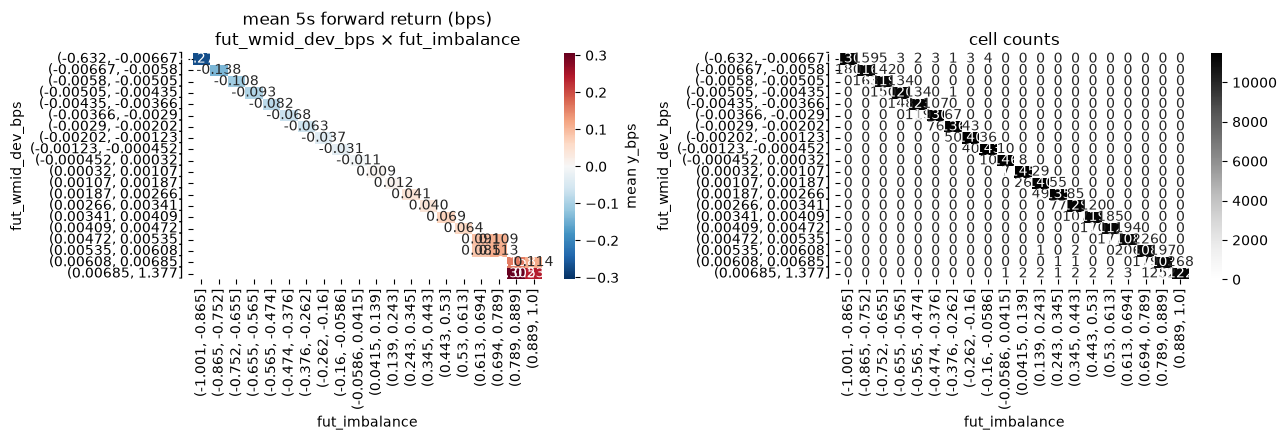

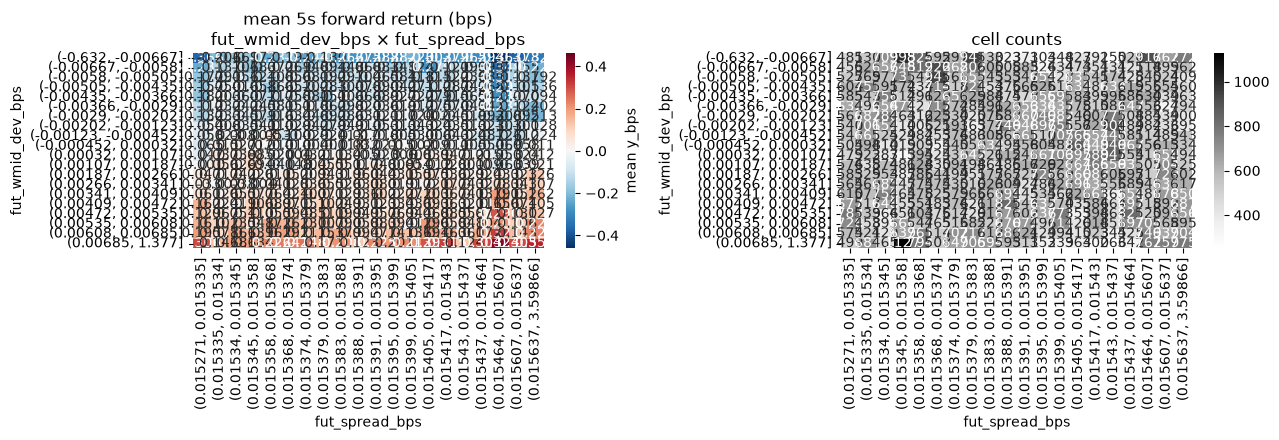

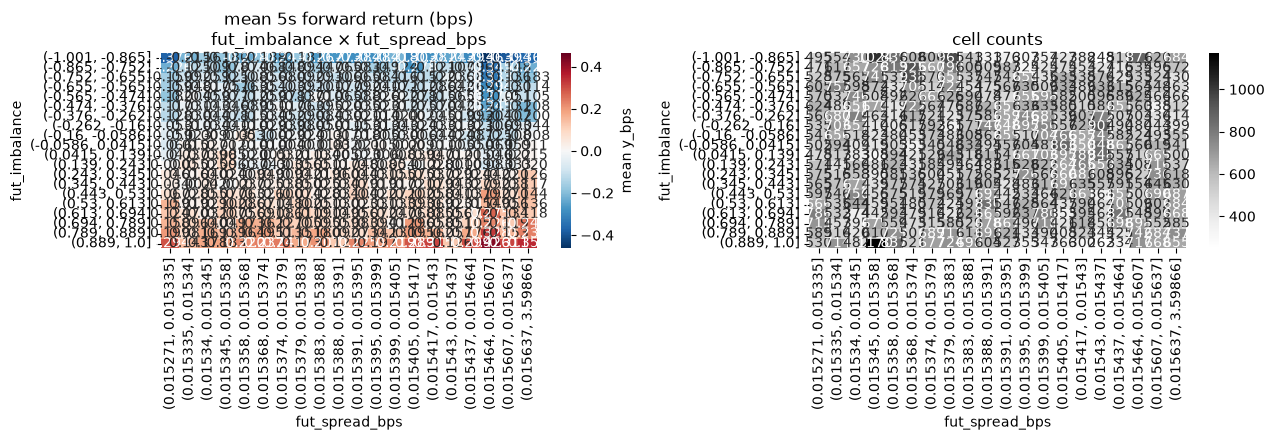

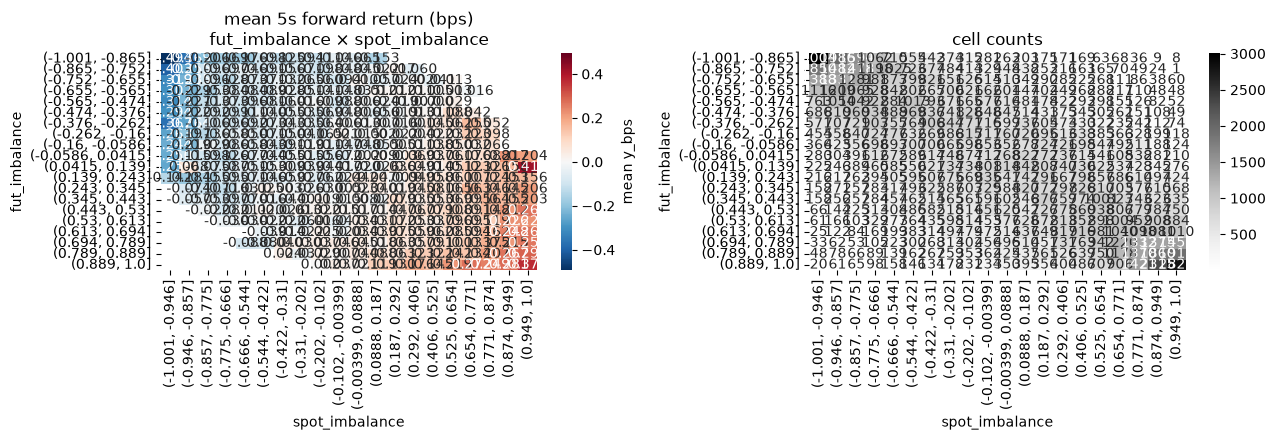

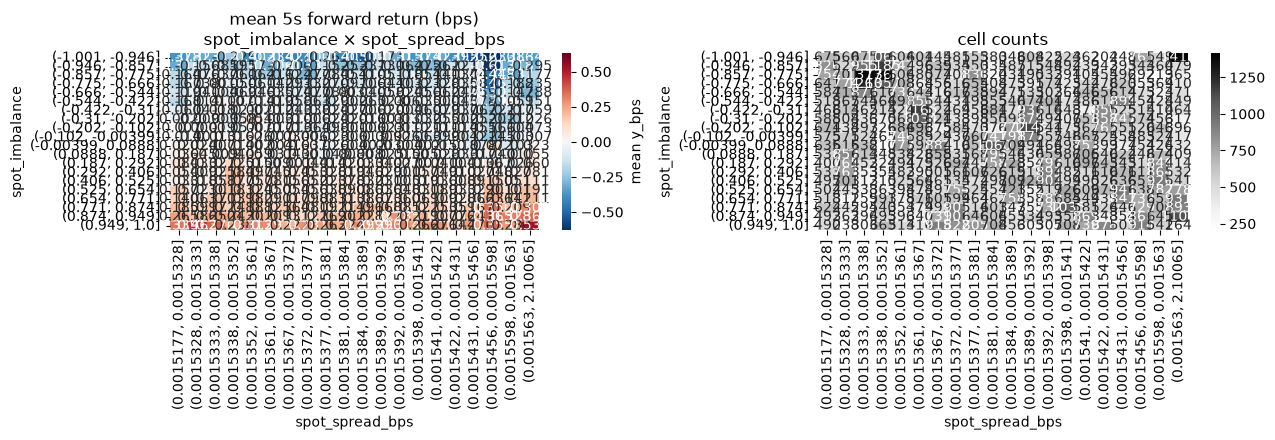

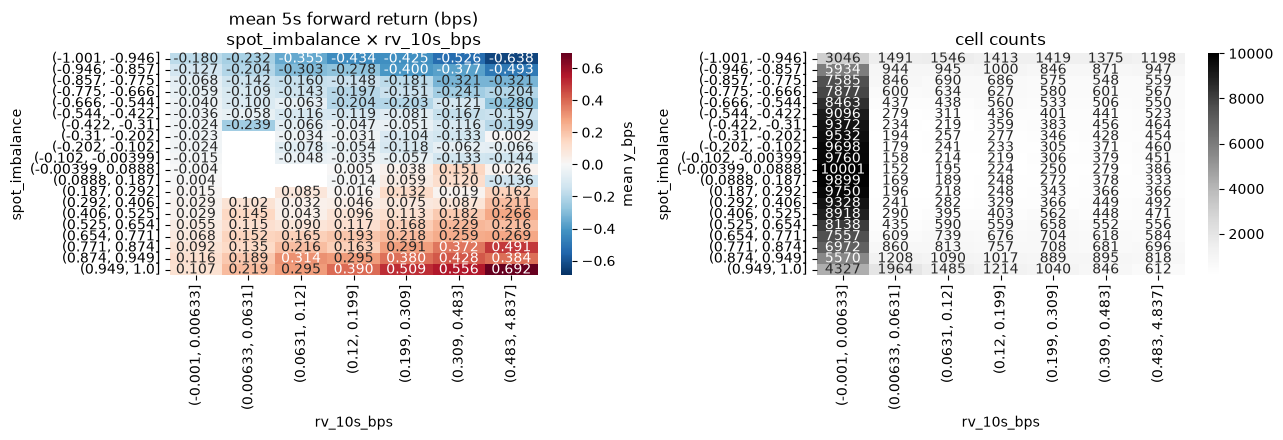

In [26]:
def interaction(f1, f2, n_bins=5, min_n=200, df=None):
    d = (df if df is not None else dev).dropna(subset=[f1, f2, "y_bps"])
    c1 = pd.qcut(d[f1], n_bins, duplicates="drop")
    c2 = pd.qcut(d[f2], n_bins, duplicates="drop")

    mean = pd.crosstab(c1, c2, values=d["y_bps"], aggfunc="mean")
    n    = pd.crosstab(c1, c2)
    mean = mean.mask(n < min_n)          # blank cells too sparse to trust

    lim = np.nanmax(np.abs(mean.to_numpy()))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.heatmap(mean, ax=ax[0], cmap="RdBu_r", center=0, vmin=-lim, vmax=lim,
                annot=True, fmt=".3f", cbar_kws={"label": "mean y_bps"})
    ax[0].set_title(f"mean 5s forward return (bps)\n{f1} × {f2}")
    sns.heatmap(n, ax=ax[1], cmap="Greys", annot=True, fmt="d")
    ax[1].set_title("cell counts")
    plt.tight_layout(); plt.show()

interaction('fut_wmid_dev_bps','fut_imbalance',20)
interaction('fut_wmid_dev_bps','fut_spread_bps',20)
interaction('fut_imbalance','fut_spread_bps',20)
interaction('fut_imbalance','spot_imbalance',20)
interaction('spot_imbalance','spot_spread_bps',20)
interaction('spot_imbalance','rv_10s_bps',20)
    

In [17]:
dev["imb_diff"] = dev.fut_imbalance - dev.spot_imbalance
# Interaction Feature for tree based model
# No effect on linear model

#### Lagged features

- "fut_wmid_dev_bps" weighted mid trade minus mid trade
- "fut_ofi_1s" normalised signed flow

No major effect shown

In [18]:
lag_cols = []
blk = (dev.t_ns.diff() > 5e9).cumsum()          # contiguous run id
for k in (1, 2, 5):
    for src in ("fut_wmid_dev_bps", "fut_ofi_1s"):
        col = f"{src}_lag{k}"
        s = dev.groupby(blk)[src].shift(k)       # shift WITHIN blocks only
        dev[col] = s
        lag_cols.append(col)

BASE = list(F.FEATURES)                          # copy, don't alias
WITH_LAGS = BASE + lag_cols

d = dev.dropna(subset=WITH_LAGS + ["y_bps"]).reset_index(drop=True)
print(f"{len(d):,} rows after lag NaNs ({len(dev)-len(d):,} dropped)")

cv = pd.concat([run_cv(d, BASE, "baseline"),
                run_cv(d, WITH_LAGS, "with lags")])
print(cv.round(5).to_string(index=False))
print(cv.groupby("model").r2_zero.agg(["mean", "std"]).round(5).to_string())

229,731 rows after lag NaNs (15 dropped)
    model  fold  r2_zero      ic  ic_spearman  dir_acc_gt_1.0bp  n_gt_1.0bp  rmse_bps     n
 baseline     0  0.01596 0.15519      0.31657           0.77255         510   0.25890 38288
 baseline     1  0.03484 0.18444      0.35927           0.83247         579   0.28442 38288
 baseline     2  0.03754 0.22881      0.43641           0.79421        3246   0.72708 38288
 baseline     3  0.07813 0.28931      0.47511           0.80791        3337   0.59199 38288
 baseline     4  0.05667 0.25006      0.40604           0.76048        5607   0.90686 38291
with lags     0  0.01598 0.15557      0.31666           0.76667         510   0.25889 38288
with lags     1  0.03539 0.18590      0.35890           0.82729         579   0.28434 38288
with lags     2  0.03781 0.22880      0.43770           0.79606        3246   0.72698 38288
with lags     3  0.07866 0.28993      0.47613           0.80821        3337   0.59182 38288
with lags     4  0.05810 0.25341      0

### Stability of each fold

- Folds rise with training size
- improves with each day
- Quiet markets are genuinely weaker

more data is better

In [19]:
print(cv[cv.model=="baseline"][["fold","r2_zero","ic","dir_acc_gt_1.0bp","n"]].round(4).to_string(index=False))

 fold  r2_zero     ic  dir_acc_gt_1.0bp     n
    0   0.0160 0.1552            0.7725 38288
    1   0.0348 0.1844            0.8325 38288
    2   0.0375 0.2288            0.7942 38288
    3   0.0781 0.2893            0.8079 38288
    4   0.0567 0.2501            0.7605 38291


In [20]:
preds = []
for i, (tr, va) in enumerate(S.purged_walk_forward(d, n_splits=5)):
    m = M.make_model()
    m.fit(d.iloc[tr][BASE], d.iloc[tr]["y_bps"])
    preds.append(pd.DataFrame({
        "t": d.iloc[va]["t"].values,
        "y": d.iloc[va]["y_bps"].values,
        "p": m.predict(d.iloc[va][BASE]),
    }))
oos = pd.concat(preds, ignore_index=True)

by_day = oos.groupby(oos.t.dt.date).apply(lambda g: pd.Series(S.evaluate(g.y, g.p, theta=1.0)))
print(by_day[["r2_zero","ic","n"]].round(4).to_string())

            r2_zero      ic        n
t                                   
2026-08-08   0.0034  0.1366  19099.0
2026-08-09   0.0266  0.1632  86114.0
2026-08-10   0.0605  0.2605  86230.0


In [21]:
oos["rv"] = d.iloc[np.concatenate([va for _, va in
             S.purged_walk_forward(d, n_splits=5)])]["rv_60s_bps"].values
oos["regime"] = pd.qcut(oos.rv, 3, labels=["quiet","mid","busy"])
print(oos.groupby("regime", observed=True).apply(
      lambda g: pd.Series(S.evaluate(g.y, g.p, theta=1.0)))[["r2_zero","ic","n"]]
      .round(4).to_string())

        r2_zero      ic        n
regime                          
quiet    0.0142  0.1389  63815.0
mid      0.0646  0.2672  63819.0
busy     0.0524  0.2393  63809.0


### Final holdout check

In [23]:
d_final = dev.dropna(subset=BASE + ["y_bps"]).reset_index(drop=True)
h_final = hold.dropna(subset=BASE + ["y_bps"]).reset_index(drop=True)
print(f"fit on {len(d_final):,} rows; evaluating on {len(h_final):,} "
      f"({len(hold)-len(h_final):,} holdout rows dropped for NaN)")

final = M.make_model()
final.fit(d_final[BASE], d_final["y_bps"])

pred = final.predict(h_final[BASE])
print(S.evaluate(h_final["y_bps"], pred, theta=1.0))
print(S.theta_sensitivity(h_final["y_bps"], pred).round(4).to_string(index=False))
print("zero-benchmark r2_zero:", S.evaluate(h_final["y_bps"], np.zeros(len(h_final)))["r2_zero"])

fit on 229,746 rows; evaluating on 57,453 (0 holdout rows dropped for NaN)
{'r2_zero': np.float64(0.07904235297694517), 'ic': np.float64(0.28693265597591344), 'ic_spearman': np.float64(0.424819052157439), 'dir_acc_gt_1.0bp': 0.8006117377174536, 'n_gt_1.0bp': 5231, 'rmse_bps': 0.6733675060771372, 'n': 57453}
 theta_bps     n  pct_of_sample  dir_acc
      0.10 13702         0.2385   0.8170
      0.25 11515         0.2004   0.8129
      0.50  8791         0.1530   0.8042
      1.00  5231         0.0910   0.8006
      2.00  1806         0.0314   0.7957
      5.00    89         0.0015   0.6854
zero-benchmark r2_zero: 0.0


C:\btc-collector\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\btc-collector\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\btc-collector\.venv\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


In [24]:
# 1. Does the model beat "predict the sign of current imbalance"?
naive = np.sign(h_final.spot_imbalance)
big = h_final.y_bps.abs() > 1.0
print("naive imbalance-sign DA:", (np.sign(h_final.y_bps[big]) == naive[big]).mean())

# 2. Prediction scale: is it shrinking to near-zero?
print(f"pred std {pred.std():.4f} vs y std {h_final.y_bps.std():.4f}")

naive imbalance-sign DA: 0.798700057350411
pred std 0.1608 vs y std 0.7017


## Final Results

Check each model for each measure of success

In [25]:
import model as M
tbl = M.results_table(d_final, BASE, n_splits=5, theta=1.0)
print(tbl.to_string())
M.verdict(tbl)

                 r2_zero_mean  r2_zero_std  ic_mean   ic_std  dir_acc     rmse  beats_naive_by
model                                                                                         
zero                  0.00000      0.00000      NaN      NaN  0.00000  0.56837         0.51569
naive imbalance      -0.51569      0.40073  0.18561  0.06272  0.79235  0.66298         0.00000
ridge                 0.04463      0.02365  0.22157  0.05302  0.79352  0.55384         0.56032
lightgbm              0.06400      0.03626  0.26348  0.06300  0.76869  0.54659         0.57969

lightgbm - ridge = +0.01937 r2_zero;  fold sigma = 0.03626
-> improvement is INSIDE fold noise. Not evidence lightgbm is better; prefer the simpler model.
